# Сравнение матчеров на проводах ЛЭП

RoMa v1, RoMa v2, LoFTR, UFM и DISK + LightGlue сопоставляют одни и те же пары снимков. YOLO-seg и SAM 2.1 создают маски проводов. По ним измеряем, сколько отмеченных точек модель смогла сопоставить и какая доля предсказаний попала рядом с проводом на втором снимке.

Используются полные папки `data/etl-2/Defect` и `data/etl-2/Normal`. Название папки обозначает источник кадра. В `Defect` есть и кадры без дефектов. Метрики относятся к сопоставлению, место дефекта и соответствующие точки по длине провода здесь не размечены.

## 1. Данные и последовательный запуск

Сначала YOLO11n-seg обучается выделять класс `cable` по полигонам TTPLA. Кадры одного ролика целиком относятся либо к обучению, либо к валидации. YOLO-seg проходит все снимки из обоих паков. Затем SAM 2.1 Tiny использует рамки и точки из масок YOLO. При пустой разметке YOLO подсказки SAM дают протяжённые линии, найденные OpenCV. Маски этих кадров требуют особенно внимательной проверки.

Кандидатов в пары ищем среди ближайших снимков одной серии по именам файлов. SIFT с геометрической проверкой отбрасывает пары без достаточного общего содержимого. Для одного кадра допускается до двух пар. Одиночные кадры всё равно получают разметку. Выбор пар по видимым деталям может смещать результат в пользу сцен с текстурным фоном.

Запуск загружает одну модель за раз и освобождает память после неё. Маски и результаты каждой пары сохраняются в `data/etl-2/wire_benchmark`. Повторный прогон продолжает с сохранённых результатов. На Mac с MPS запускайте ядро с переменной окружения `PYTORCH_ENABLE_MPS_FALLBACK=1`.

In [1]:
import os
import sys
from pathlib import Path

os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")
notebook_dir = Path.cwd() if (Path.cwd() / "wire_benchmark.py").is_file() else Path.cwd() / "notebooks"
sys.path.insert(0, str(notebook_dir.resolve()))

from wire_benchmark import project_root, run
from wire_data import build_pairs, read_manifest, read_rgb, SIDE
from wire_masks import load_masks, mask_path
from wire_matching import MASK_NAMES, MODEL_NAMES, read_results, result_path

import json
import cv2
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import numpy as np
import pandas as pd
from IPython.display import display

root = project_root()
work = root / "data" / "etl-2" / "wire_benchmark"
run(root)

frames = read_manifest(root / "data" / "etl-2")
pairs = build_pairs(frames, work)
paired_keys = {key for pair in pairs for key in (pair.a, pair.b)}
inventory = pd.DataFrame([
    {"папка": frame.pack, "кадр": key, "есть пара": key in paired_keys}
    for key, frame in frames.items()
])
display(inventory.groupby("папка").agg(кадров=("кадр", "size"), с_парой=("есть пара", "sum")))
display(pd.Series([frames[pair.a].pack for pair in pairs]).value_counts().rename("пар").to_frame())

Пары: 237, кадров с партнёром: 419/869.


RoMa v1: все 237 пары уже рассчитаны.


RoMa v2: все 237 пары уже рассчитаны.


LoFTR: все 237 пары уже рассчитаны.


UFM: все 237 пары уже рассчитаны.


DISK + LightGlue: все 237 пары уже рассчитаны.


,кадров,с_парой
папка,,
defect,433,277
normal,436,142


,пар
defect,156
normal,81


## 2. Маски YOLO-seg и SAM

Для каждого сегментатора показываем число обработанных кадров, число кадров с непустой маской и визуальные примеры. IoU показывает, насколько совпадают две автоматические разметки. SAM здесь использует подсказки от YOLO, поэтому согласие двух моделей само по себе не подтверждает точность масок. Полигонов, проверенных вручную для всех кадров этих паков, нет.

При проверке примеров SAM с геометрическими подсказками выделяла и части опор. Такие маски сохраняются с пометкой `line`.

обработано  с_маской
pack   mask                      
defect sam          433       425
       yolo         433       416
normal sam          436       436
       yolo         436       434

pack    prompts
defect  line        16
        none         1
        yolo       416
normal  line         2
        yolo       434
Name: кадров, dtype: int64

,count,median
pack,,
defect,432,0.342
normal,436,0.422


,epoch,metrics/mAP50(M),metrics/mAP50-95(M)
5,6,0.0453,0.0089


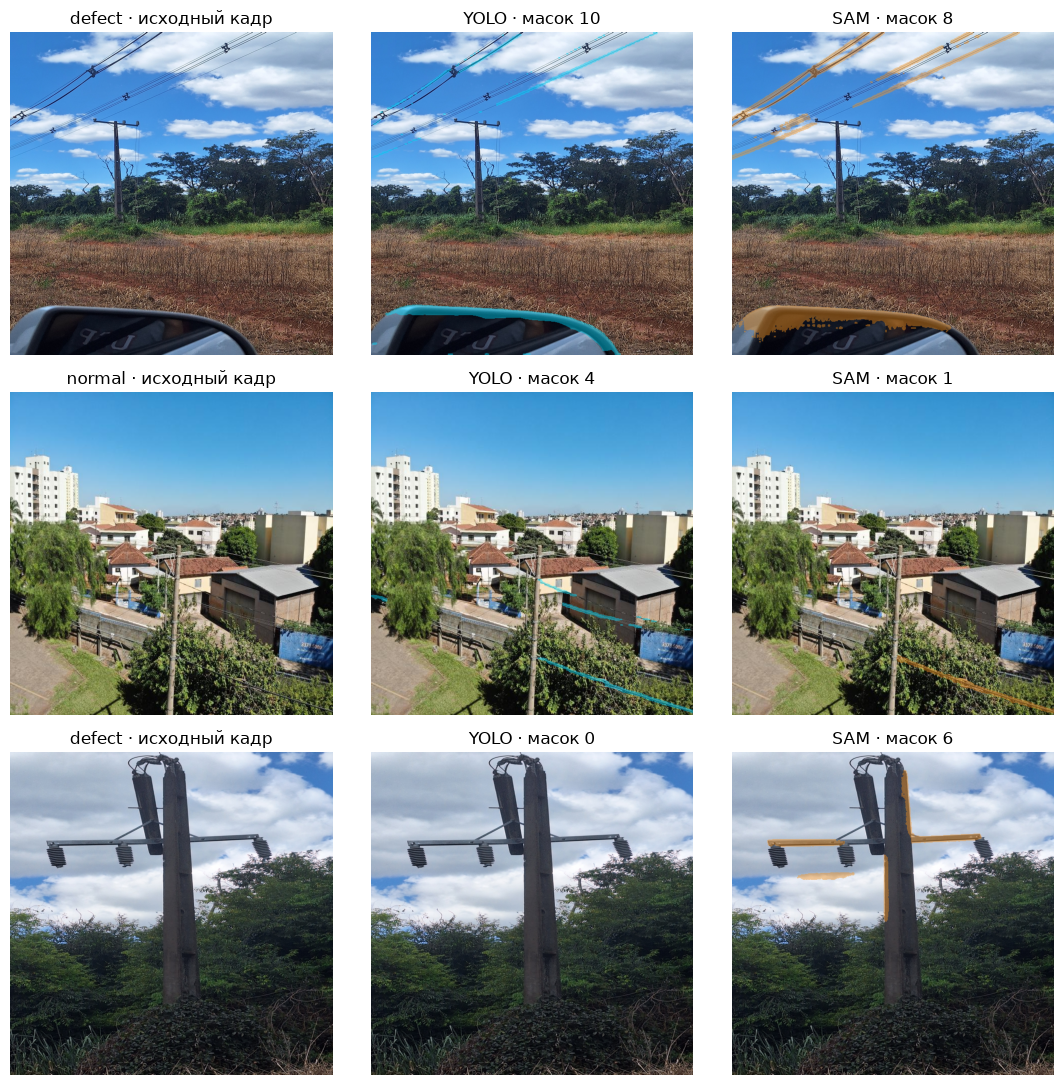

In [2]:
annotations = []
agreement = []
for key, frame in frames.items():
    unions = {}
    for method in MASK_NAMES:
        path = mask_path(work, method, frame)
        masks = load_masks(path)
        unions[method] = masks.any(axis=0)
        with np.load(path, allow_pickle=False) as saved:
            prompts = str(saved["prompts"])
        annotations.append({"frame": key, "pack": frame.pack, "mask": method,
                            "instances": len(masks), "pixels": int(unions[method].sum()),
                            "prompts": prompts})
    union = (unions["yolo"] | unions["sam"]).sum()
    if union:
        ratio = (unions["yolo"] & unions["sam"]).sum() / union
        agreement.append({"frame": key, "pack": frame.pack, "IoU": ratio})

masks_table = pd.DataFrame(annotations)
masks_table.to_csv(work / "mask_inventory.csv", index=False)
display(masks_table.assign(непустых=masks_table.pixels.gt(0))
        .groupby(["pack", "mask"]).agg(обработано=("frame", "size"), с_маской=("непустых", "sum")))
display(masks_table.query("mask == 'sam'").groupby(["pack", "prompts"]).size().rename("кадров"))
if agreement:
    display(pd.DataFrame(agreement).groupby("pack")["IoU"].agg(["count", "median"]).round(3))

training = pd.read_csv(work / "train-wire" / "results.csv")
display(training[["epoch", "metrics/mAP50(M)", "metrics/mAP50-95(M)"]].tail(1).round(4))


def mask_overlay(image, mask, color):
    canvas = image.copy()
    highlight = cv2.dilate(mask.astype(np.uint8), np.ones((3, 3), np.uint8)).astype(bool)
    canvas[highlight] = (0.55 * image[highlight] + 0.45 * np.array(color)).astype(np.uint8)
    return canvas


def show_masks(*keys):
    fig, axes = plt.subplots(len(keys), 3, figsize=(11, 3.65 * len(keys)), squeeze=False)
    for row, key in zip(axes, keys):
        frame = frames[key]
        image = read_rgb(frame.path)
        row[0].imshow(image)
        row[0].set_title(f"{frame.pack} · исходный кадр")
        for ax, method, color in zip(row[1:], MASK_NAMES, ([0, 220, 255], [244, 146, 32])):
            instances = load_masks(mask_path(work, method, frame))
            ax.imshow(mask_overlay(image, instances.any(axis=0), color))
            ax.set_title(f"{method.upper()} · масок {len(instances)}")
        for ax in row:
            ax.axis("off")
    fig.tight_layout()
    plt.show()


overlap_examples = pd.DataFrame(agreement)
if not overlap_examples.empty:
    example_keys = []
    for _, group in overlap_examples.groupby("pack"):
        group = group.sort_values("IoU")
        example_keys.append(group.iloc[len(group) // 2]["frame"])
    fallback_example = "defect/20250307_143148.jpg"
    if fallback_example in frames:
        example_keys.append(fallback_example)
    show_masks(*example_keys)

## 3. Метрики сопоставления

Модель получает два RGB-кадра. Метрики считаются по одинаковым исходным точкам на маске в каждом прогоне. В каждой ячейке сетки 8 × 8 px выбираем одну точку внутри маски, всего до 256 точек на кадр. Считаем направление A → B по порядку кадров в паре.

- **Покрытие** — доля исходных точек, для которых есть принятое соответствие. У плотных моделей используем их оценку видимости или уверенности выше 0,5. Для LoFTR и DISK + LightGlue ищем ближайшую выданную ключевую точку в пределах 6 px.
- **Попадания среди принятых** — доля принятых соответствий, попавших в пределах 6 px от маски провода на B на сетке 640 × 640.
- **Попадания среди всех** — доля всех исходных точек, для которых есть попадание. Пропуски и промахи снижают показатель.
- **Время** — медиана времени инференса на пару, без загрузки модели и расчёта метрик.

Маски YOLO и SAM дают два повторных расчёта метрик поверх одних и тех же выходов матчера. В общей таблице ниже одинаковый набор пар с непустой разметкой обоих сегментаторов. Шкалы уверенности моделей могут различаться. Попадание рядом с маской может засчитать соседний провод и ничего не говорит о сдвиге вдоль провода.

RoMa v1 Outdoor работает с грубой сеткой 448 px и уточнением 640 px. RoMa v2 использует режим `fast`. LoFTR Outdoor и DISK + LightGlue получают кадры размером 640 px. Для DISK задано до 2048 ключевых точек на кадр. UFM использует веса Base DINOv2-L.

пар  с_двумя_масками
pack   mask                      
defect sam   156              145
       yolo  156              144
normal sam    81               81
       yolo   81               81

Пар с общей разметкой двух сегментаторов: 217 из 237


pairs  seconds  покрытие  попадания среди принятых  \
mask model                                                                  
sam  DISK + LightGlue    217    0.141     0.125                     0.594   
     LoFTR               217    0.242     0.510                     0.634   
     RoMa v1             217    1.167     0.213                     0.597   
     RoMa v2             217    0.245     0.559                     0.596   
     UFM                 217    0.377     0.731                     0.581   
yolo DISK + LightGlue    217    0.141     0.114                     0.603   
     LoFTR               217    0.242     0.485                     0.674   
     RoMa v1             217    1.167     0.185                     0.672   
     RoMa v2             217    0.245     0.550                     0.649   
     UFM                 217    0.377     0.713                     0.589   

                       попадания среди всех  
mask model                                   
sam  DISK + LightGlue                 0.074  
     LoFTR                            0.323  
     RoMa v1                          0.127  
     RoMa v2                          0.333  
     UFM                              0.424  
yolo DISK + LightGlue                 0.069  
     LoFTR                            0.327  
     RoMa v1                          0.124  
     RoMa v2                          0.357  
     UFM                              0.420

pairs  seconds  покрытие  \
pack   mask model                                        
defect sam  DISK + LightGlue    136    0.146     0.063   
            LoFTR               136    0.233     0.420   
            RoMa v1             136    1.170     0.146   
            RoMa v2             136    0.244     0.456   
            UFM                 136    0.380     0.700   
       yolo DISK + LightGlue    136    0.146     0.060   
            LoFTR               136    0.233     0.400   
            RoMa v1             136    1.170     0.133   
            RoMa v2             136    0.244     0.469   
            UFM                 136    0.380     0.685   
normal sam  DISK + LightGlue     81    0.129     0.228   
            LoFTR                81    0.268     0.660   
            RoMa v1              81    1.161     0.323   
            RoMa v2              81    0.247     0.728   
            UFM                  81    0.374     0.781   
       yolo DISK + LightGlue     81    0.129     0.211   
            LoFTR                81    0.268     0.640   
            RoMa v1              81    1.161     0.278   
            RoMa v2              81    0.247     0.697   
            UFM                  81    0.374     0.762   

                              попадания среди принятых  попадания среди всех  
pack   mask model                                                             
defect sam  DISK + LightGlue                     0.515                 0.032  
            LoFTR                                0.613                 0.257  
            RoMa v1                              0.589                 0.086  
            RoMa v2                              0.588                 0.268  
            UFM                                  0.578                 0.405  
       yolo DISK + LightGlue                     0.484                 0.029  
            LoFTR                                0.628                 0.251  
            RoMa v1                              0.591                 0.079  
            RoMa v2                              0.637                 0.299  
            UFM                                  0.566                 0.388  
normal sam  DISK + LightGlue                     0.630                 0.144  
            LoFTR                                0.655                 0.432  
            RoMa v1                              0.604                 0.195  
            RoMa v2                              0.604                 0.439  
            UFM                                  0.585                 0.456  
       yolo DISK + LightGlue                     0.665                 0.141  
            LoFTR                                0.726                 0.465  
            RoMa v1                              0.742                 0.206  
            RoMa v2                              0.664                 0.463  
            UFM                                  0.626                 0.477

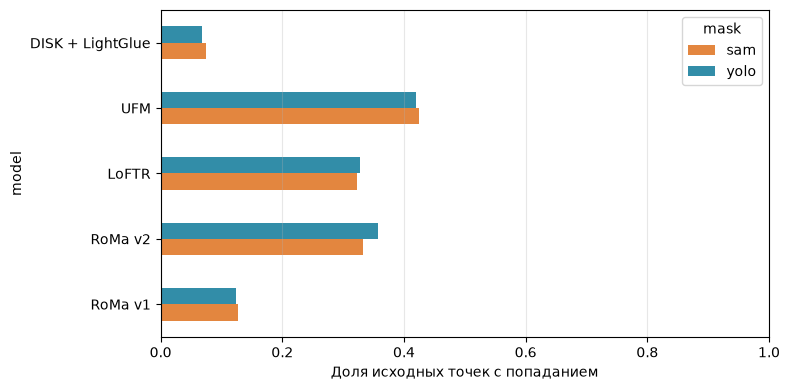

In [3]:
scores = read_results(work, pairs)
assert len(scores) == len(MODEL_NAMES) * len(MASK_NAMES) * len(pairs)
scores.to_csv(work / "match_metrics.csv", index=False)

available = scores[scores.model.eq(MODEL_NAMES[0])]
display(available.groupby(["pack", "mask"]).eligible.agg(пар="size", с_двумя_масками="sum"))
common = available.groupby("pair").eligible.all()
common_keys = common[common].index
comparable = scores.loc[scores.pair.isin(common_keys)].copy()
print(f"Пар с общей разметкой двух сегментаторов: {len(common_keys)} из {len(pairs)}")


def aggregate(data, by):
    totals = data.groupby(by).agg(
        pairs=("pair", "size"),
        anchors=("anchors", "sum"),
        accepted=("accepted", "sum"),
        hits=("hits", "sum"),
        seconds=("seconds", "median"),
    )
    totals["покрытие"] = totals.accepted / totals.anchors
    totals["попадания среди принятых"] = totals.hits / totals.accepted.replace(0, np.nan)
    totals["попадания среди всех"] = totals.hits / totals.anchors
    return totals.drop(columns=["anchors", "accepted", "hits"])


summary = aggregate(comparable, ["mask", "model"])
summary.to_csv(work / "model_summary.csv")
display(summary.round(3))
display(aggregate(comparable, ["pack", "mask", "model"]).round(3))

if not summary.empty:
    plot = summary["попадания среди всех"].unstack("mask").reindex(MODEL_NAMES)
    ax = plot.plot.barh(figsize=(8, 4), xlim=(0, 1), color=["#e3863f", "#328da8"])
    ax.set_xlabel("Доля исходных точек с попаданием")
    ax.grid(axis="x", alpha=0.3)
    plt.tight_layout()
    plt.show()

## 4. Визуальная проверка пар

Выбери пару из таблицы или передай её идентификатор в `show_pair`. На каждом ряду слева кадр A, справа кадр B. Зелёные линии попали в маску с допуском, красные промахнулись. На рисунке отображается до 24 принятых соответствий на модель для читаемости. Пропущенные точки учитываются в покрытии.

,pair,pack,A,B,SIFT inliers,обе маски
0,6536fcfc0c7c97f18e,defect,1 (588).JPG,1 (606).JPG,22,True
1,dd51c6982cdb8e1d08,defect,20190301_150806-008_jpg.rf.5e411d71369aacec1d6...,20190301_150806-009_jpg.rf.785cc8e34a384a70889...,26,True
2,394b924862d120101b,defect,20190301_150806-009_jpg.rf.785cc8e34a384a70889...,20190301_150806-010_jpg.rf.2121989e800d0c50605...,22,True
3,def441158fe141279c,defect,20190301_150806-011_jpg.rf.2383eb8640cad11bf69...,20190301_150806-012_jpg.rf.7d85202ae880641b87d...,19,True
4,ca76dc813d6afdd230,defect,20190301_150806-013_jpg.rf.6b4de42b6dbf7df6eb9...,20190301_150806-014_jpg.rf.1b04e60b98b221c4929...,16,True
5,a87032ab84377a431b,defect,20190301_150806-015_jpg.rf.03374172308c4e55c2d...,20190301_150806-016_jpg.rf.7194cb8ebb65db4f955...,55,True
6,cfbcb6d2631077bb9a,defect,20190301_150806-017_jpg.rf.ca2ef8d1d6e8922d2e8...,20190301_150806-018_jpg.rf.6af1b24dc66cf3bd3c5...,112,False
7,709c66da301168b19c,defect,20190301_150806-019_jpg.rf.e312bbe8e8d69ccc2da...,20190301_150806-021_jpg.rf.ccf6371b42a3e27f4d6...,88,True
8,adee97e47a75269749,defect,20190301_150806-022_jpg.rf.c1f0c95046ea216da55...,20190301_150806-023_jpg.rf.6adffdbdd5662604d7d...,135,True
9,56fa5e2e1801d439df,defect,20190301_150806-024_jpg.rf.8963db19da3959d7f01...,20190301_150806-025_jpg.rf.7155025a82a61a90198...,126,True


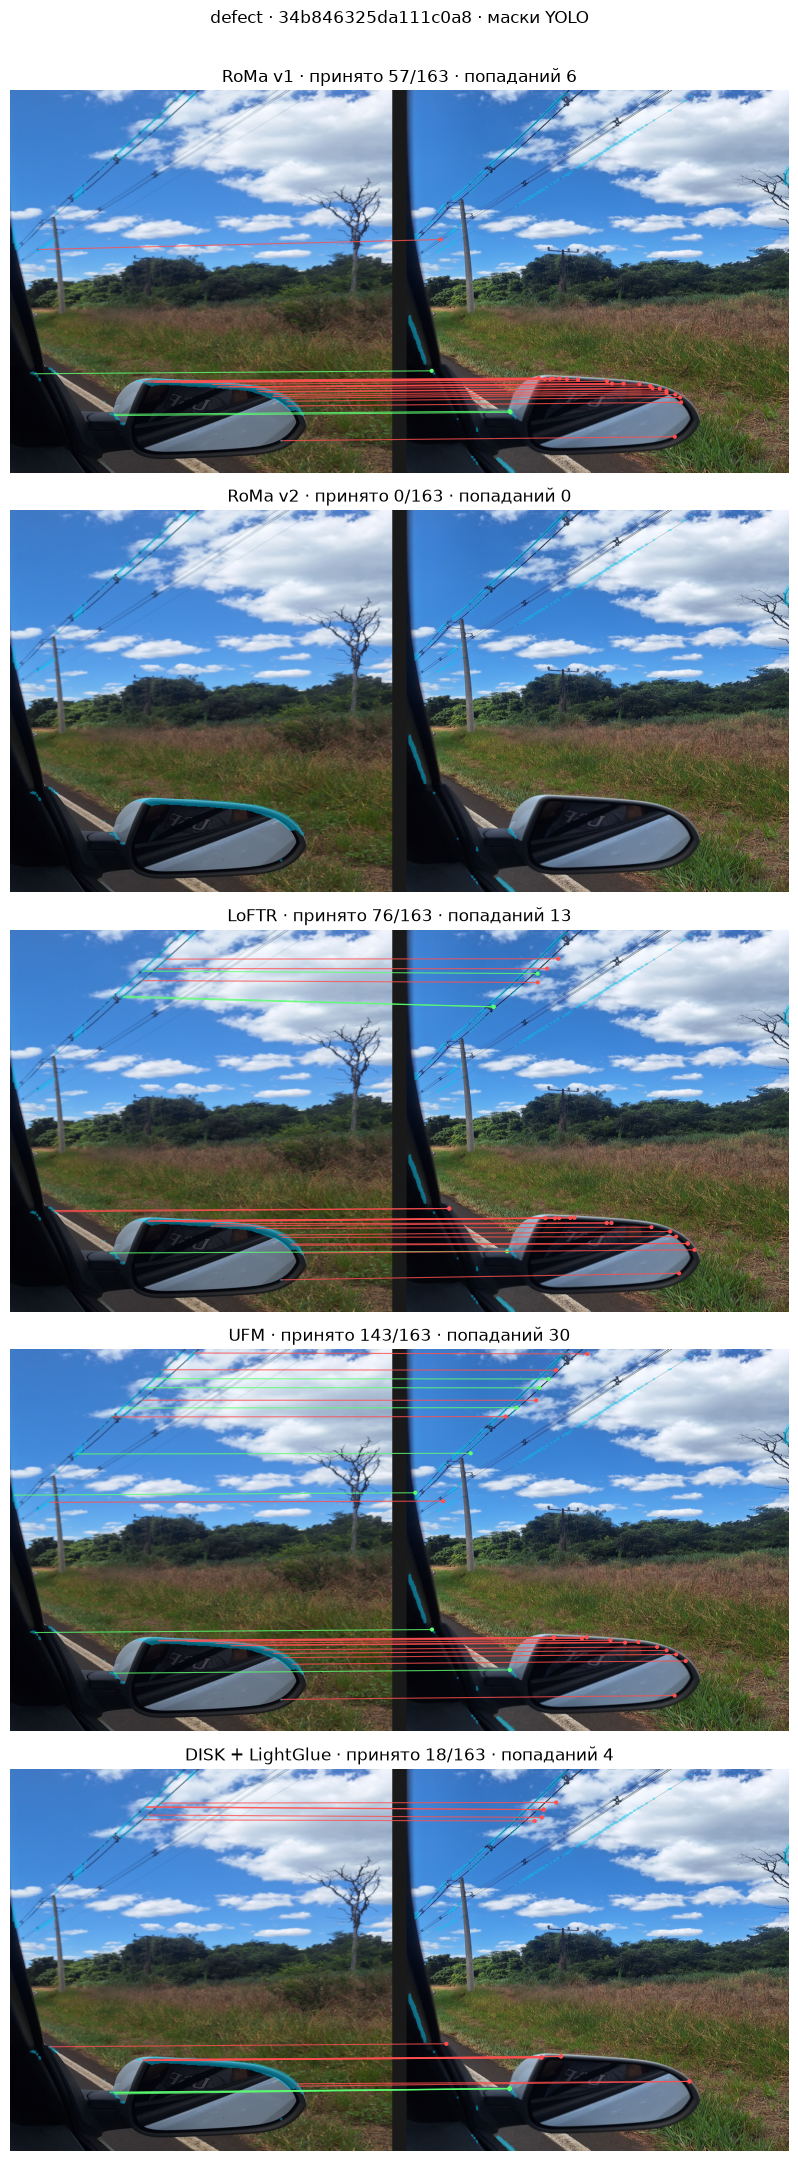

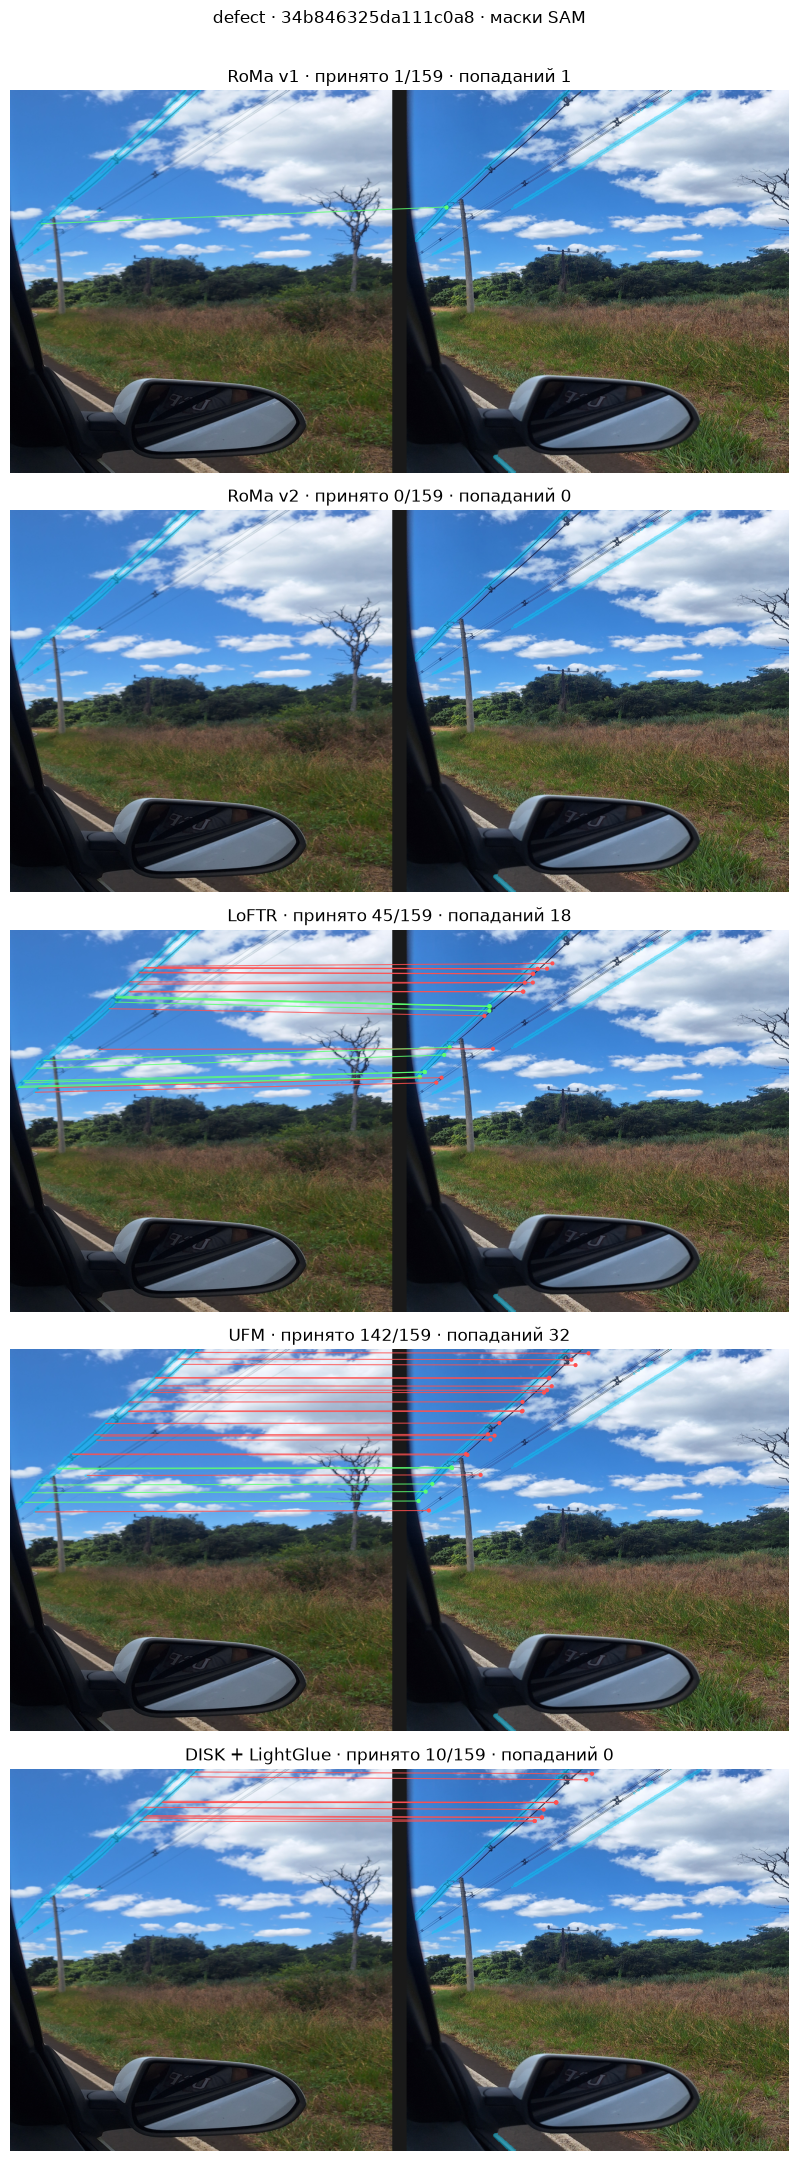

In [4]:
pair_table = pd.DataFrame([
    {"pair": pair.key, "pack": frames[pair.a].pack, "A": frames[pair.a].path.name,
     "B": frames[pair.b].path.name, "SIFT inliers": pair.inliers,
     "обе маски": pair.key in common_keys}
    for pair in pairs
])
display(pair_table.head(10))
paired_by_key = {pair.key: pair for pair in pairs}


def show_pair(pair_key, method="yolo"):
    pair = paired_by_key[pair_key]
    a, b = [frames[key] for key in (pair.a, pair.b)]
    gap = 24
    offset = SIDE + gap
    canvas = np.full((SIDE, 2 * SIDE + gap, 3), 25, dtype=np.uint8)
    for frame, start in ((a, 0), (b, offset)):
        image = read_rgb(frame.path)
        mask = load_masks(mask_path(work, method, frame)).any(axis=0)
        canvas[:, start:start + SIDE] = mask_overlay(image, mask, [0, 210, 255])

    fig, axes = plt.subplots(len(MODEL_NAMES), figsize=(11, 4.4 * len(MODEL_NAMES)))
    for ax, name in zip(axes, MODEL_NAMES):
        result = json.loads(result_path(work, name, pair).read_text())
        numbers = result["metrics"][method]
        ax.imshow(canvas)
        points = np.asarray(result["points"][method], dtype=float).reshape(-1, 5)
        inside = ((points[:, 2:4] >= -0.5) & (points[:, 2:4] < SIDE - 0.5)).all(axis=1)
        points = points[inside]
        if len(points):
            selected = points[np.linspace(0, len(points) - 1, min(24, len(points)), dtype=int)]
            targets = selected[:, 2:4] + (offset, 0)
            colors = np.where(selected[:, 4], "#5cff71", "#ff5050")
            ax.add_collection(LineCollection(np.stack((selected[:, :2], targets), axis=1),
                                             colors=colors, linewidths=0.8, alpha=0.8))
            ax.scatter(*targets.T, c=colors, s=9, linewidths=0)
        ax.set_title(f"{name} · принято {numbers['accepted']}/{numbers['anchors']}"
                     f" · попаданий {numbers['hits']}")
        ax.set_xlim(-0.5, canvas.shape[1] - 0.5)
        ax.set_ylim(SIDE - 0.5, -0.5)
        ax.axis("off")
    fig.suptitle(f"{a.pack} · {pair.key} · маски {method.upper()}")
    fig.tight_layout(rect=(0, 0, 1, 0.975))
    plt.show()


examples = pair_table[pair_table["обе маски"]]
if not examples.empty:
    center = examples.sort_values("SIFT inliers").iloc[len(examples) // 2]
    show_pair(center["pair"], "yolo")
    show_pair(center["pair"], "sam")

## Вывод по сохранённому прогону

UFM дала наибольшую долю попаданий среди всех исходных точек на 217 общих парах. По маскам YOLO-seg результат составил **42,0%**, по маскам SAM — **42,4%**. У LoFTR самая высокая доля попаданий среди принятых соответствий в общей выборке, а у UFM самое высокое покрытие. RoMa v2 обошла RoMa v1 по доле попаданий среди всех точек в обоих вариантах разметки.

Качество автоматической разметки ограничивает интерпретацию результатов. У YOLO-seg масочный mAP@0.5 на отложенных роликах TTPLA составил около 4,5%. В протоколе проверяется близость к маске любого провода. Для точности вдоль конкретного провода нужны эталонные пары точек.

## Воспроизведение

Эксперимент использует локальные `romatch`, `romav2`, `kornia`, `ultralytics`, `jaxtyping`, `scikit-learn` и `termcolor`. В рабочем каталоге `data/etl-2/wire_benchmark` нужны веса `sam2.1_t.pt`, репозиторий UFM с подмодулем UniCeption в `ufm-source` и файлы `config.json`, `model.safetensors` из UFM Base DINOv2-L в `ufm-weights`. Использовался UFM commit `ff78d6c3db807c91578acccb58ee67d4394d5e5f`. Веса YOLO для проводов создаются первой ячейкой из TTPLA.

[TTPLA](https://arxiv.org/abs/2010.10032) · [Ultralytics](https://docs.ultralytics.com/tasks/segment/) · [SAM 2](https://github.com/facebookresearch/sam2) · [UFM](https://github.com/UniFlowMatch/UFM) · [Веса UFM](https://huggingface.co/infinity1096/UFM-Base-DINOv2L-init)